# code_030 · Transfer, adaptation and learning across tasks

**Book:** section 6.4. These are synthetic mechanism experiments, not observed structural performance, safety assessment, a causal study or an estimator leaderboard. Each experiment states which cases are unseen and which outcomes are available. Fits and preprocessing use training observations only. Development curves support diagnosis; final outcomes are opened only after the stated rule is fixed. Constructed identities and stress cases are not held-out population estimates.

Restart and run all cells. All imports, helpers and data generation are here; no ordinary-run files, network, API key, GPU or private module is required. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [traceability guide](../CHAPTER_06_GUIDE.md), [execution evidence](../CHAPTER_06_EXECUTION.md) and [permanent registry](../CODE_EXAMPLES.md#code_030). Reference environment: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute for execution and 30–60 minutes for interpretation. These scoped labs disclose relevant controls rather than cover every constructor parameter.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=630;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 630


<a id="tasks"></a>
## A task distribution supplies reusable experience

Each task is one independent synthetic building response y=a*x+b+noise sd .06 mm, with fixed dimensionless load x in [-1,1]. Slopes a are normal(1.4,.35) mm and offsets b normal(.2,.7) mm. Generate 80 source tasks, each with six support and twelve query members. These source support/query splits train adaptation mechanisms; they are not final assessment. New tasks have disjoint parameters and observations. No search over task seeds is performed.

Fit a pooled affine source predictor by least squares. Also fit an actual multitask rule with one shared slope and 80 task-specific intercepts. The known-task heads illustrate simultaneous task objectives; they do not provide a new building's intercept without calibration.


In [2]:
def generate_tasks(count,ns=6,nq=12):
 a=rng.normal(1.4,.35,count);b=rng.normal(.2,.7,count)
 xs=rng.uniform(-1,1,(count,ns));xq=rng.uniform(-1,1,(count,nq))
 ys=a[:,None]*xs+b[:,None]+rng.normal(0,.06,xs.shape);yq=a[:,None]*xq+b[:,None]+rng.normal(0,.06,xq.shape)
 return np.stack([xs,np.ones_like(xs)],axis=-1),ys,np.stack([xq,np.ones_like(xq)],axis=-1),yq
S,ys,Q,yq=generate_tasks(80);pooled=np.linalg.lstsq(S.reshape(-1,2),ys.ravel(),rcond=None)[0]
task_id=np.repeat(np.arange(80),6);joint=np.column_stack([S[:,:,0].ravel(),np.eye(80)[task_id]])
multitask=np.linalg.lstsq(joint,ys.ravel(),rcond=None)[0]
assert pooled.shape==(2,) and multitask.shape==(81,) and len(np.unique(task_id))==80
assert np.linalg.norm(joint.T@(joint@multitask-ys.ravel()))<1e-10
print('Pooled slope/intercept [mm]:',pooled,'multitask shared slope [mm]:',multitask[0])
RESULTS['pooled_coefficients_mm']=pooled.tolist();RESULTS['multitask_shared_slope_mm']=float(multitask[0])


Pooled slope/intercept [mm]: [1.30886635 0.10949298] multitask shared slope [mm]: 1.3824100189944408


<a id="meta"></a>
## Learn an initialization for one-step adaptation

Optimize the actual post-adaptation query objective. A support gradient step uses alpha=.2, mean half squared error and initialization theta. The outer update differentiates through that step, using (I-alpha*support Hessian). Meta-training: 400 full-source-task updates, outer rate .08, initial theta=(0,0). Check the analytic meta-gradient against finite differences. This is an exact tiny linear MAML mechanism, not a deep-network benchmark.


In [3]:
alpha=.2;H=np.einsum('tni,tnj->tij',S,S)/S.shape[1];J=np.eye(2)[None,:,:]-alpha*H
def meta_objective(theta,gradient=False):
 residual=np.einsum('tni,i->tn',S,theta)-ys;gs=np.einsum('tni,tn->ti',S,residual)/S.shape[1]
 adapted=theta[None,:]-alpha*gs;r=np.einsum('tni,ti->tn',Q,adapted)-yq
 loss=float(.5*np.mean(r*r));gq=np.einsum('tni,tn->ti',Q,r)/Q.shape[1]
 grad=np.einsum('tji,tj->ti',J,gq).mean(0)
 return (loss,grad) if gradient else loss
theta=np.zeros(2);loss0,analytic=meta_objective(theta,True);numerical=[]
for i in range(2):
 delta=np.eye(2)[i]*1e-6;numerical.append((meta_objective(theta+delta)-meta_objective(theta-delta))/(2e-6))
assert np.allclose(analytic,numerical,rtol=1e-6,atol=1e-8)
for step in range(400):theta-=.08*meta_objective(theta,True)[1]
assert meta_objective(theta)<loss0 and np.isfinite(theta).all()
RESULTS['meta_initial_final_query_half_MSE_mm2']=[loss0,meta_objective(theta)];RESULTS['meta_initialization_mm']=theta.tolist()


<a id="context"></a>
## A pretrained context-conditioned rule with fixed learned state

A separate RBF context predictor averages support labels using query–support distances. Its learned parameter is log bandwidth, optimized on source-task query errors for 300 updates at rate .05, clipped to [-3,2]. No external pretrained checkpoint is used. Context labels enter the fixed forward rule; no gradient or stored-weight update occurs for a new task. This tiny contextual mechanism illustrates the state distinction without implementing a transformer or claiming all forms of in-context learning.

Derivative of log kernel weight with respect to log bandwidth is squared distance / bandwidth². A finite-difference check protects the actual training mechanism. Shifting every context label by one must shift each prediction by one while leaving learned bandwidth unchanged.


In [4]:
def context_predict(logh,S,ys,Q,derivative=False):
 h=np.exp(logh);distance=(Q[:,:,None,0]-S[:,None,:,0])**2;scores=-distance/(2*h*h)
 weights=np.exp(scores-scores.max(axis=2,keepdims=True));weights/=weights.sum(axis=2,keepdims=True)
 pred=np.sum(weights*ys[:,None,:],axis=2)
 deriv=np.sum(weights*(ys[:,None,:]-pred[:,:,None])*distance/(h*h),axis=2)
 return (pred,deriv) if derivative else pred
def context_objective(logh,gradient=False):
 pred,deriv=context_predict(logh,S,ys,Q,True);r=pred-yq
 return (float(.5*np.mean(r*r)),float(np.mean(r*deriv))) if gradient else float(.5*np.mean(r*r))
logh=float(np.log(.8));context0=context_objective(logh);loss,g=context_objective(logh,True);delta=1e-6
assert np.isclose(g,(context_objective(logh+delta)-context_objective(logh-delta))/(2*delta),rtol=1e-5,atol=1e-8)
for step in range(300):logh=float(np.clip(logh-.05*context_objective(logh,True)[1],-3,2))
saved_logh=logh;assert context_objective(logh)<context0
assert np.allclose(context_predict(logh,S,ys+1,Q),context_predict(logh,S,ys,Q)+1) and logh==saved_logh
RESULTS['context_bandwidth']=float(np.exp(logh));RESULTS['context_initial_final_query_half_MSE_mm2']=[context0,context_objective(logh)]


<a id="final"></a>
## Freeze source experience; assess new tasks once

Draw 80 final tasks with six context/support rows and twenty query rows each. Compare fixed pooled weights, 100 support-only gradient updates from pooled weights (rate .2), one support step from the meta-learned initialization, and the fixed pretrained contextual rule. These are distinct predeclared mechanisms with different compute; their errors are not a fair algorithm leaderboard. Final query outcomes never adapt parameters. Metrics average query squared error within tasks, then across equally weighted tasks.


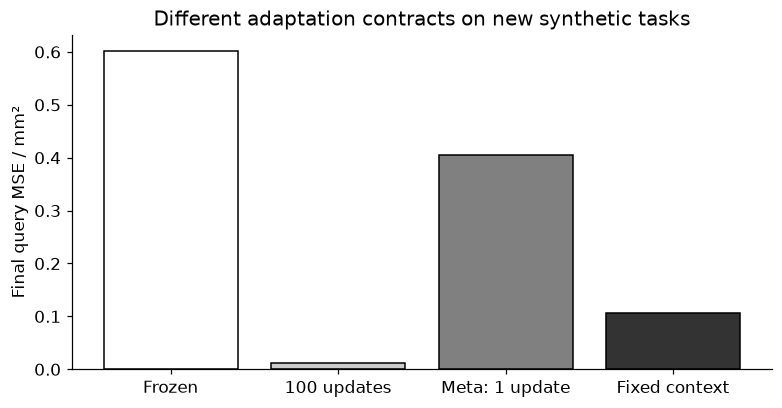

{'frozen_pooled': 0.6024365830430506, 'fine_tuned_100_steps': 0.011478926460447424, 'meta_one_step': 0.4052184751614849, 'fixed_context_rule': 0.10553753109783251}


In [5]:
Fs,Fys,Fq,Fyq=generate_tasks(80,6,20);saved_pool=pooled.copy();saved_meta=theta.copy()
fine=np.tile(pooled,(80,1))
for step in range(100):fine-=.2*np.einsum('tni,tn->ti',Fs,np.einsum('tni,ti->tn',Fs,fine)-Fys)/6
meta_adapted=theta[None,:]-.2*np.einsum('tni,tn->ti',Fs,np.einsum('tni,i->tn',Fs,theta)-Fys)/6
predictions={'frozen_pooled':np.einsum('tni,i->tn',Fq,pooled),'fine_tuned_100_steps':np.einsum('tni,ti->tn',Fq,fine),'meta_one_step':np.einsum('tni,ti->tn',Fq,meta_adapted),'fixed_context_rule':context_predict(logh,Fs,Fys,Fq)}
metrics={k:float(np.mean((pred-Fyq)**2)) for k,pred in predictions.items()}
assert np.array_equal(pooled,saved_pool) and np.array_equal(theta,saved_meta) and logh==saved_logh
assert all(pred.shape==(80,20) for pred in predictions.values()) and np.isfinite(list(metrics.values())).all()
fig,ax=plt.subplots(figsize=(7,3.6));ax.bar(np.arange(4),list(metrics.values()),color=['white','.8','.5','.2'],edgecolor='black');ax.set(xticks=np.arange(4),xticklabels=['Frozen','100 updates','Meta: 1 update','Fixed context'],ylabel='Final query MSE / mm²',title='Different adaptation contracts on new synthetic tasks');plt.show()
RESULTS['final_task_query_MSE_mm2']=metrics;print(metrics)


<a id="shift"></a>
## Stress transfer outside the source-task relationship

Use a separate declared noiseless stress task y=-2*x+1, whose slope direction differs from the source distribution. Six support rows permit weight adaptation, while an unadapted positive-slope rule retains an inappropriate preference. This constructed plot is not another final benchmark. It identifies an obvious negative-transfer risk; transfer benefit would require a matched target-only baseline and development-controlled comparison.


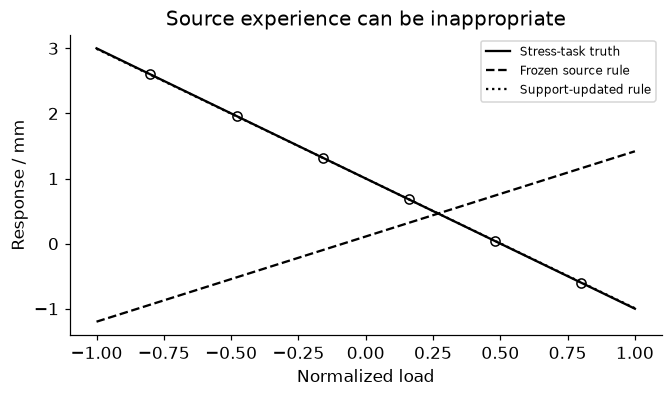

In [6]:
xs=np.linspace(-.8,.8,6);Sshift=np.column_stack([xs,np.ones(6)]);yshift=-2*xs+1;wshift=pooled.copy()
for step in range(100):wshift-=.2*Sshift.T@(Sshift@wshift-yshift)/6
xline=np.linspace(-1,1,150);Xline=np.column_stack([xline,np.ones(150)])
assert np.mean((Sshift@wshift-yshift)**2)<np.mean((Sshift@pooled-yshift)**2)
fig,ax=plt.subplots(figsize=(6,3.5));ax.plot(xline,-2*xline+1,'k-',label='Stress-task truth');ax.plot(xline,Xline@pooled,'k--',label='Frozen source rule');ax.plot(xline,Xline@wshift,'k:',label='Support-updated rule');ax.scatter(xs,yshift,marker='o',facecolors='white',edgecolors='black');ax.set(xlabel='Normalized load',ylabel='Response / mm',title='Source experience can be inappropriate');ax.legend(fontsize=8);plt.show()
RESULTS['shift_task_support_MSE_frozen_updated_mm2']=[float(np.mean((Sshift@pooled-yshift)**2)),float(np.mean((Sshift@wshift-yshift)**2))]


<a id="exercises"></a>
## Exercises and hints

1. Reduce source-task diversity without changing row count. Evaluate transfer on development tasks, then use new final tasks for selected settings.
2. Add target-only training with a matched label and compute budget before claiming positive or negative transfer.
3. Distinguish fixed stored parameters, temporary adapted coefficients, context inputs and per-query outputs in each method.
4. Make query loads lie beyond all context loads. Stress context interpolation rather than assuming universal few-shot transfer.
5. Compare pooled learning, simultaneous shared-task heads and post-update meta-objectives. Which labels affect which weights?

**Hints:** pretraining describes reusable prior learning, fine-tuning updates stored trainable state, frozen features retain their encoder, and context changes a fixed predictor's input. Meta-learning trains an adaptation mechanism over tasks. This implements exact tiny linear [MAML](https://proceedings.mlr.press/v70/finn17a.html), not a pretrained transformer. Keep task identity and support/query boundaries explicit.


In [7]:
summary={'example_id':'code_030','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['pooled pretraining frozen and updated weights', 'actual one-step meta-learned initialization', 'learned fixed context-conditioned predictor', 'multi-task shared slope and task heads', 'task-disjoint final assessment and negative-transfer stress'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["pooled pretraining frozen and updated weights", "actual one-step meta-learned initialization", "learned fixed context-conditioned predictor", "multi-task shared slope and task heads", "task-disjoint final assessment and negative-transfer stress"], "elapsed_seconds": 0.171, "example_id": "code_030", "hardware": "Darwin arm64 CPU", "results": {"context_bandwidth": 0.2701044608492857, "context_initial_final_query_half_MSE_mm2": [0.1834623332332446, 0.04261266438929887], "final_task_query_MSE_mm2": {"fine_tuned_100_steps": 0.011478926460447424, "fixed_context_rule": 0.10553753109783251, "frozen_pooled": 0.6024365830430506, "meta_one_step": 0.4052184751614849}, "meta_initial_final_query_half_MSE_mm2": [0.4875938633485949, 0.19475813841148545], "meta_initialization_mm": [1.4006001034919817, 0.09372836756245555], "multitask_shared_slope_mm": 1.3824100189944408, "pooled_coefficients_mm": [1.3088663473498994, 0.10949298282517456], "shift_task_s